<a href="https://colab.research.google.com/github/ayishathanha53-eng/AI-ML-lab/blob/main/k-means%20%2C%20ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

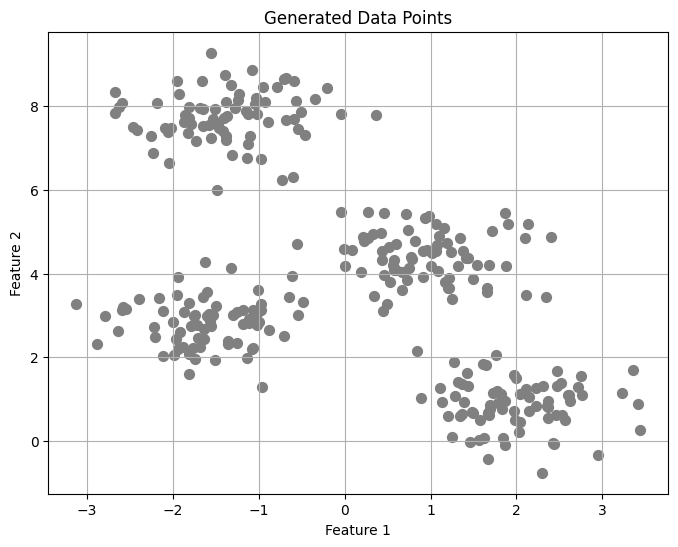

In [ ]:
# k-means clustering algorithm
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# Generate synthetic 2D data with 4 clusters
X, y = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

# Plot the raw data points
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50, color='gray')
plt.title("Generated Data Points")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)
plt.show()

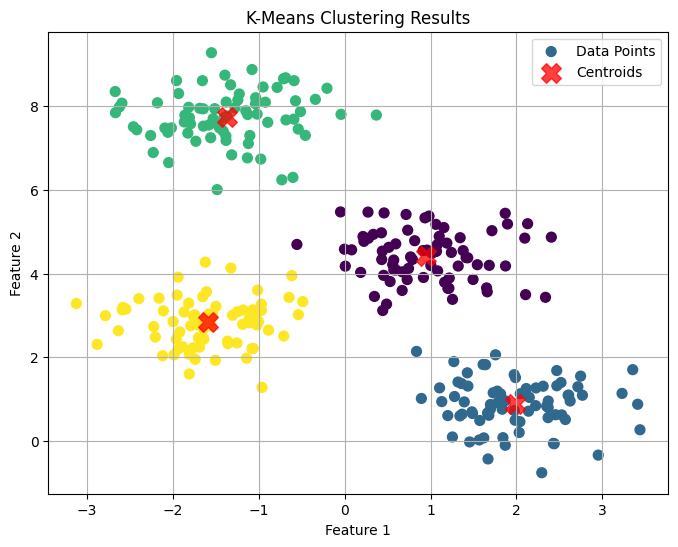

In [ ]:
# Initialize KMeans with 4 clusters
kmeans = KMeans(n_clusters=4, random_state=0, n_init='auto')

# Fit the model and predict clusters
y_kmeans = kmeans.fit_predict(X)

# Get cluster centers
centers = kmeans.cluster_centers_

# Plot the clustered data along with the cluster centroids
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis', label='Data Points')
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.75, marker='X', label='Centroids')
plt.title("K-Means Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

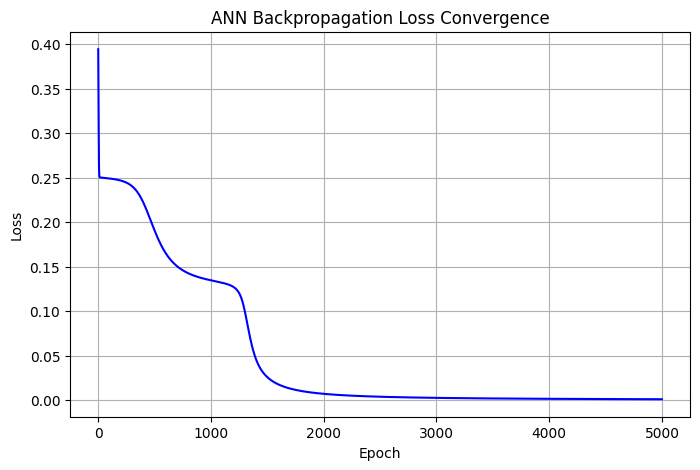

Predictions after training:
Input: [0 0] -> Predicted: 0.0165 (Target: 0)
Input: [0 1] -> Predicted: 0.9678 (Target: 1)
Input: [1 0] -> Predicted: 0.9639 (Target: 1)
Input: [1 1] -> Predicted: 0.0415 (Target: 0)


In [1]:
# ANN
import numpy as np
import matplotlib.pyplot as plt

# Activation function and its derivative
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# Generate a simple XOR-like dataset for classification
X_ann = np.array([[0,0], [0,1], [1,0], [1,1]])
y_ann = np.array([[0], [1], [1], [0]])

# Seed for reproducibility
np.random.seed(42)

# Network Architecture
input_size = 2
hidden_size = 3
output_size = 1
learning_rate = 0.5
epochs = 5000

# Initialize weights and biases randomly
weights_hidden = np.random.uniform(size=(input_size, hidden_size))
bias_hidden = np.random.uniform(size=(1, hidden_size))
weights_output = np.random.uniform(size=(hidden_size, output_size))
bias_output = np.random.uniform(size=(1, output_size))

losses = []

# Training Loop (Backpropagation)
for epoch in range(epochs):
    # Forward Propagation
    hidden_activation = np.dot(X_ann, weights_hidden) + bias_hidden
    hidden_output = sigmoid(hidden_activation)

    output_activation = np.dot(hidden_output, weights_output) + bias_output
    predicted_output = sigmoid(output_activation)

    # Calculate Error (MSE Loss)
    error = y_ann - predicted_output
    loss = np.mean(np.square(error))
    losses.append(loss)

    # Backward Propagation
    # Error term for output layer
    d_predicted_output = error * sigmoid_derivative(predicted_output)

    # Error term for hidden layer
    error_hidden = d_predicted_output.dot(weights_output.T)
    d_hidden_output = error_hidden * sigmoid_derivative(hidden_output)

    # Updating weights and biases
    weights_output += hidden_output.T.dot(d_predicted_output) * learning_rate
    bias_output += np.sum(d_predicted_output, axis=0, keepdims=True) * learning_rate
    weights_hidden += X_ann.T.dot(d_hidden_output) * learning_rate
    bias_hidden += np.sum(d_hidden_output, axis=0, keepdims=True) * learning_rate

# Plot Loss Over Epochs
plt.figure(figsize=(8, 5))
plt.plot(losses, color='blue')
plt.title("ANN Backpropagation Loss Convergence")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# Print final predictions
print("Predictions after training:")
for i in range(len(X_ann)):
    print(f"Input: {X_ann[i]} -> Predicted: {predicted_output[i][0]:.4f} (Target: {y_ann[i][0]})")